# Task 2: Model Baseline and Data Preparation
## Air Quality Sensor Calibration · WS 2026/27

**Ziel:** `pm25_target` (µg/m³) mit linearer Regression schätzen und den Effekt der Datenvorbereitung nachvollziehbar prüfen.

Grundlage sind ausschließlich die bereitgestellte Case Study, Python Labs, Vorlesungen und das alte Projekt mit Feedback. Die Struktur des alten Projekts (Einlesen → begründete Module → Vergleich → Test → Export) bleibt erhalten; fachliche Bike-Rental-Regeln werden nicht übernommen.

**Reihenfolge:** Aufgabenregeln → Split und Diagnose → modulare Vorbereitung → Baseline → Einzelmaßnahmen → vollständige Kombinationen → Auswahl anhand Validation → einmaliger Test → CSV-Übergabe und Learnings.

Die konkreten Task-1-Ergebnisse des aktuellen Teams liegen nicht im Ordner. Deshalb folgt eine eigene, ausdrücklich vorläufige Diagnose ausschließlich des Trainingsteils. Sie ersetzt keine Abstimmung mit Task 1.

## 1. Verbindliche Regeln und begründete Entscheidungen

- Maßgeblich: **Case Study Description, Seite 8** (aktuelle Task 2), Seiten 10–11 (Abgabe). Seite 15 enthält ältere Tipps mit wiederholter Testbewertung und Feature Selection. Wir folgen Seite 8 und dem Feedback: **keine Feature Selection in Task 2**, Modellauswahl nur auf Validation.
- **Alle 16 ursprünglichen Features** sind in der Baseline vertreten. Numerische Messgrößen: Mittelwert-Imputation; `timestamp`: numerische Zeitdarstellung; `year_month`: One-Hot-Encoding. Diese technische Mindestvorbereitung ist für lineare Regression notwendig.
- Zeitlich geordneter **80/20-Split** der gelieferten Trainingsdatei mit `train_test_split(..., shuffle=False)`. Annahme: spätere Messungen sollen aus früheren gelernt werden. So gelangen unmittelbar spätere Stunden nicht zufällig ins Training. Es wird kein zusätzlicher Zeitabstand erzwungen; zeitliche Abhängigkeit bleibt eine Einschränkung.
- Nur Trainingszeilen ohne Zielwert werden vom Fit ausgeschlossen. Validation und Test behalten **alle Zeilen, Reihenfolge und Labels**, einschließlich eventueller NaN-Labels. Vorhersagen für alle; Metriken nur für vorhandene Labels, mit offengelegtem Nenner.
- Imputation, Ausreißergrenzen, Transformationsparameter, OHE-Kategorien und Skalierung lernen nur aus dem Training. Kein Label wird als Eingabe genutzt.
- Ausschließlich `LinearRegression()`; keine Algorithmenwahl, Polynome oder Hyperparameteroptimierung.
- Auswahl vor Testzugriff: kleinstes Validation-MAE; Unterschiede bis 10⁻⁸ gelten als numerisch gleich, dann gewinnt die einfachere Vorbereitung. R² und Overfitting-Abstand werden zusätzlich berichtet.

**Quellennachweis:** `QUELLEN_UND_ENTSCHEIDUNGEN.md` ordnet jeden Baustein seinen lokalen Vorlagen zu. Anpassungen und zusätzlicher Organisations-/Prüfcode sind dort ausdrücklich gekennzeichnet.

## 2. Imports und reproduzierbare Pfade
Die Bibliotheken stammen aus den Labs bzw. dem alten Notebook. `Path`, Ausgabeordner und Prüfungen dienen lediglich der portablen Ausführung. In VS Code den Kernel mit den Paketen aus `requirements.txt` wählen und **Run All** ausführen.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

BASE = Path.cwd()
if not (BASE / 'data' / 'pm25_train.csv').exists():
    BASE = BASE / 'Task2_Data_Preparation'
DATA = BASE / 'data'
RESULTS = BASE / 'results'
FIGURES = BASE / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
TARGET = 'pm25_target'
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
pd.set_option('display.max_columns', 20)
print('Python:', sys.version.split()[0])
print('Arbeitsordner:', BASE)

Python: 3.12.14
Arbeitsordner: /Users/kevin/Documents/ChatGPT/Data Science Projekt/Task2_Data_Preparation


## 3. Training einlesen und Validation abtrennen
Quelle: altes Notebook, Datenimport und Split; Pipeline-Demo, `train_test_split`. `shuffle=False` ist die bewusst dokumentierte Anpassung für die vorliegenden Zeitstempel. Die Testdatei wird erst nach der Auswahl eingelesen.

In [2]:
original_train = pd.read_csv(DATA / 'pm25_train.csv')
assert original_train.shape == (3613, 17)
assert pd.to_datetime(original_train['timestamp']).is_monotonic_increasing
assert original_train['timestamp'].is_unique
raw_train, validation = train_test_split(original_train, test_size=0.2, shuffle=False)
# Lab Missing Value Handling: fehlende Labels nur im TRAINING vom Fit ausschließen.
training = raw_train.loc[raw_train[TARGET].notna()].copy()
validation = validation.copy()
validation_labels_before = validation[TARGET].copy()
validation_index_before = validation.index.copy()
FEATURES = [c for c in original_train.columns if c != TARGET]
SENSOR_FEATURES = [c for c in FEATURES if c not in ['timestamp', 'year_month']]
assert len(FEATURES) == 16
assert len(SENSOR_FEATURES) == 14
assert set(training.index).isdisjoint(validation.index)

split_summary = pd.DataFrame([
    {'Teil': 'Training vor Labelprüfung', 'Zeilen': len(raw_train), 'Labels vorhanden': raw_train[TARGET].notna().sum(), 'Start': raw_train.timestamp.iloc[0], 'Ende': raw_train.timestamp.iloc[-1]},
    {'Teil': 'Training für Fit', 'Zeilen': len(training), 'Labels vorhanden': training[TARGET].notna().sum(), 'Start': training.timestamp.iloc[0], 'Ende': training.timestamp.iloc[-1]},
    {'Teil': 'Validation unverändert', 'Zeilen': len(validation), 'Labels vorhanden': validation[TARGET].notna().sum(), 'Start': validation.timestamp.iloc[0], 'Ende': validation.timestamp.iloc[-1]},
])
display(split_summary)
split_summary.to_csv(RESULTS / 'split_summary.csv', index=False)
pd.DataFrame({'source_row': raw_train.index[raw_train[TARGET].isna()], 'reason': 'pm25_target fehlt; kein überwachtes Training möglich'}).to_csv(RESULTS / 'excluded_training_rows.csv', index=False)

,Teil,Zeilen,Labels vorhanden,Start,Ende
0,Training vor Labelprüfung,2890,2686,2024-06-03 11:00:00,2024-10-01 20:00:00
1,Training für Fit,2686,2686,2024-06-03 11:00:00,2024-10-01 20:00:00
2,Validation unverändert,723,723,2024-10-01 21:00:00,2024-10-31 23:00:00


## 4. Vorläufiger Anschluss an Task 1: Datenqualität im Fit-Training
Quelle: Pandas Exploration, Missing-Value-Lab, Outlier-Lab und Transformation-Script. Keine inhaltliche Exploration der Validation oder Testdaten zur Auswahl von Regeln. Ausreißer sind zunächst statistische Auffälligkeiten, keine nachgewiesenen Sensorfehler.

In [3]:
diagnosis = training[SENSOR_FEATURES].describe().T
missing = training[SENSOR_FEATURES].isna().sum()
diagnosis['missing_n'] = missing
diagnosis['missing_pct'] = 100 * missing / len(training)
diagnosis['skew'] = training[SENSOR_FEATURES].skew()
q1 = training[SENSOR_FEATURES].quantile(0.25)
q3 = training[SENSOR_FEATURES].quantile(0.75)
iqr = q3 - q1
flagged = (training[SENSOR_FEATURES] < q1 - 1.5 * iqr) | (training[SENSOR_FEATURES] > q3 + 1.5 * iqr)
diagnosis['iqr_flagged_n'] = flagged.sum()
display(diagnosis.round(3))
diagnosis.to_csv(RESULTS / 'training_diagnosis.csv')
print('Doppelte vollständige Trainingszeilen:', training.duplicated().sum())
print('Negative NO-Messwerte:', int((training['no'] < 0).sum()))
print('Label im Training:')
display(training[TARGET].describe().to_frame())

,count,mean,std,min,25%,50%,75%,max,missing_n,missing_pct,skew,iqr_flagged_n
pm25_lowcost,2360.0,4.238,15.225,0.300,1.600,2.550,4.340,436.420,326,12.137,22.017,144
no,2676.0,5.934,42.273,-2.700,0.200,1.100,3.100,1131.700,10,0.372,18.502,277
no2,2676.0,7.679,6.747,0.300,3.100,6.200,10.500,94.800,10,0.372,3.579,73
o3,2478.0,26.822,13.698,0.500,15.825,26.100,36.275,78.600,208,7.744,0.344,3
co2,2353.0,459.971,22.649,427.500,442.500,454.600,473.900,701.200,333,12.398,1.842,23
black_carbon,2686.0,0.796,1.296,0.045,0.316,0.558,0.902,36.684,0,0.000,12.927,163
ufp,2110.0,9764.755,4966.834,2077.700,6685.600,9075.450,11874.225,110138.800,576,21.445,5.115,55
temperature,2295.0,18.916,4.599,5.937,15.684,18.721,21.991,33.166,391,14.557,0.151,15
relative_humidity,2295.0,71.469,14.518,35.542,60.751,74.258,83.827,94.688,391,14.557,-0.527,0
pressure,2295.0,1008.359,5.932,985.906,1004.572,1007.955,1012.104,1024.010,391,14.557,-0.064,42


Doppelte vollständige Trainingszeilen: 0
Negative NO-Messwerte: 429
Label im Training:


,pm25_target
count,2686.000000
mean,3.385652
std,2.323551
min,0.240000
25%,1.720000
50%,2.705000
75%,4.497500
max,15.560000


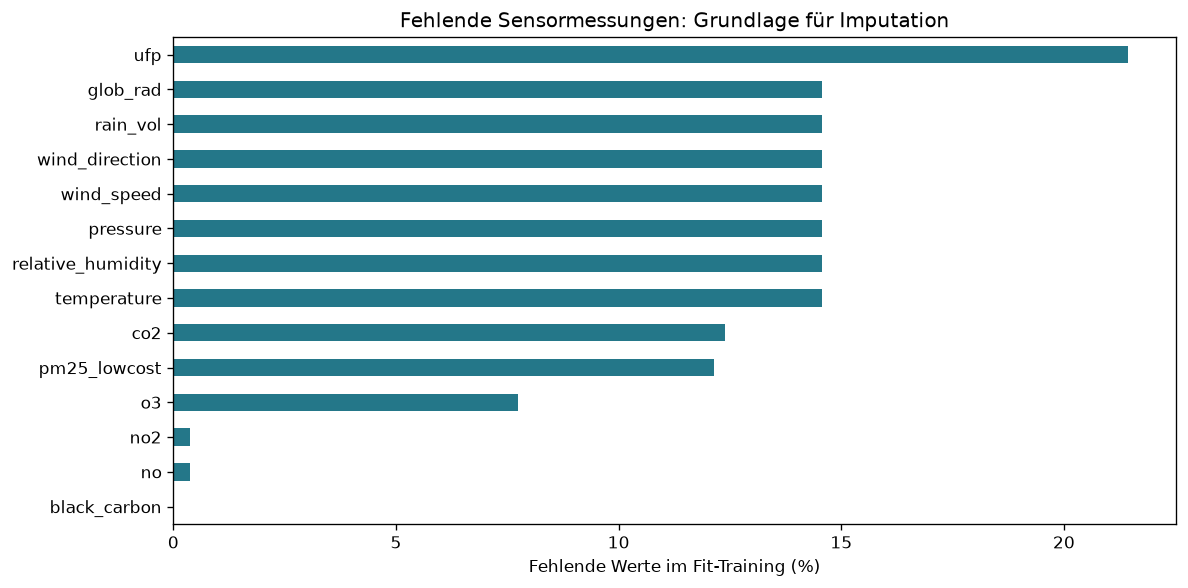

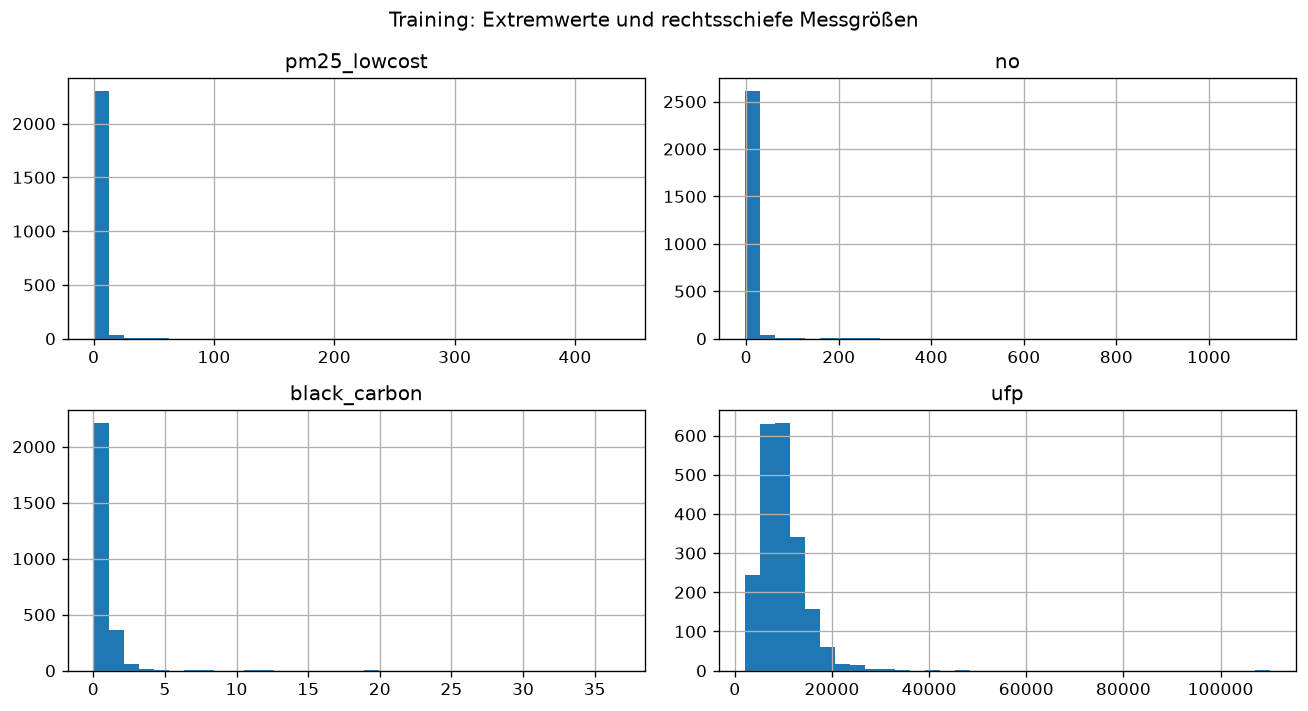

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
(100 * missing / len(training)).sort_values().plot.barh(ax=ax, color='#247789')
ax.set_xlabel('Fehlende Werte im Fit-Training (%)')
ax.set_title('Fehlende Sensormessungen: Grundlage für Imputation')
fig.tight_layout()
fig.savefig(FIGURES / 'missing_training.png', bbox_inches='tight')
plt.show()
training[['pm25_lowcost', 'no', 'black_carbon', 'ufp']].hist(bins=35, figsize=(11, 6))
plt.suptitle('Training: Extremwerte und rechtsschiefe Messgrößen')
plt.tight_layout()
plt.savefig(FIGURES / 'distributions_training.png', bbox_inches='tight')
plt.show()

### Maßnahmen und Hypothesen vor der Modellauswahl

| Maßnahme | Begründung | Risiko / Kontrolle |
|---|---|---|
| Mittelwert → Median | Fehlende Messungen; Ausreißer können Mittelwerte verschieben | Median verliert Zusammenhänge zwischen Sensoren; Effekt messen |
| IQR-Ausreißer → NaN → Imputation | Große Spitzen bei Schadstoffsensoren | Reale Belastungsspitzen können verloren gehen; optionaler Versuch, keine pauschale Fehlerbehauptung |
| PowerTransformer | Schiefe kontinuierliche Messgrößen; mögliche nichtlineare Zusammenhänge | Ändert Abstände und Beziehungen; normalverteilte Features sind für OLS nicht zwingend nötig |
| Windrichtung zyklisch | Wertebereich legt Winkel in Grad nahe; 0° und 360° sind benachbart | Grad ist eine aus Daten abgeleitete Annahme, keine dokumentierte Einheit; zwei Komponenten ersetzen den Winkel |
| StandardScaler | Sehr unterschiedliche Einheiten; Kontrolle der Aussage des alten Projekts | Bei unregularisierter OLS mit Intercept kein systematischer MAE-Gewinn zu erwarten |

**Nicht übernommen:** Bike-Rental-Regeln, Entfernen korrelierter Features, automatische Löschung von Messspitzen, künstliche Zielwertkorrekturen. Negative NO-Werte bleiben mangels Sensor-Dokumentation zunächst erhalten; ihre Bewertung als Fehler wäre nicht belegt. Nullwerte bei Strahlung oder Regen sind keine automatischen Missings. `rain_vol` wird ohne dokumentierte Messdefinition nicht differenziert.

**Versuchsraum:** 2 Imputationen × 2 Ausreißeroptionen × 2 Power-Optionen × 2 Windoptionen × 2 Scaling-Optionen = **32** Varianten. Jede optionale Maßnahme wird allein relativ zur minimalen Baseline geprüft, außerdem jede Kombination. OHE und technische Datumsumwandlung sind in allen Varianten identische Mindestvorbereitung. OH kann technisch nicht ohne anschließende Imputation eingesetzt werden.

## 5. Module: minimale Repräsentation und zyklische Windrichtung
Quelle: `pd.to_datetime` aus dem alten Projekt; OHE und Sinus/Cosinus aus `TRANSFORMATION_SCRIPT`; getrenntes Fit/Transform aus Pipeline-Demo. Der Zeitstempel wird als Tage seit Trainingsbeginn dargestellt, nicht als tausende einzelne Kategorien. Sein Informationsgehalt bleibt im Modell; `year_month` bleibt zusätzlich als Kategorie enthalten. Redundanz wird als Grenze dokumentiert, nicht durch Feature Selection beseitigt.

Bei zyklischer Windrichtung werden zuerst Sinus und Cosinus berechnet, danach fehlende Komponenten imputiert. Ein imputierter Vektor darf innerhalb des Einheitskreises liegen; er wird nicht als beobachtete Windrichtung interpretiert.

In [5]:
def represent_features(df, origin, cyclic=False):
    """Deterministische Repräsentation ohne Zugriff auf das Label."""
    X = df[FEATURES].copy()
    timestamp = pd.to_datetime(X['timestamp'])
    X['timestamp_days'] = (timestamp - origin).dt.total_seconds() / 86400
    X = X.drop(columns='timestamp')
    if cyclic:
        X['wind_direction_sin'] = np.sin(2 * np.pi * X['wind_direction'] / 360)
        X['wind_direction_cos'] = np.cos(2 * np.pi * X['wind_direction'] / 360)
        X = X.drop(columns='wind_direction')
    return X

## 6. Module: Ausreißerbehandlung mit Trainingsgrenzen
Quelle: `Pipeline_Demo2_with_OutlierHandlingClass`, IQR-Zweig, und Outlier-Vorlesung, Seiten 8–9. **Korrektur gegenüber dem Demo:** Quartile werden in `fit_outliers` gespeichert, nicht bei jedem Aufruf auf Validation/Test neu berechnet. Es werden nur einzelne Featurewerte ersetzt; keine Zeile und kein Label wird entfernt oder verändert.

Die IQR-Regel wird auf die sieben Schadstoffmessgrößen angewendet. Kalenderwerte, Winkel und meteorologische Größen werden nicht pauschal als Ausreißer behandelt. Faktor 1,5 stammt aus der Demo und wird nicht optimiert.

In [6]:
OUTLIER_FEATURES = ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp']

def fit_outliers(X):
    Q1 = X[OUTLIER_FEATURES].quantile(0.25)
    Q3 = X[OUTLIER_FEATURES].quantile(0.75)
    IQR = Q3 - Q1
    return pd.DataFrame({'lower': Q1 - 1.5 * IQR, 'upper': Q3 + 1.5 * IQR})

def apply_outliers(X, bounds):
    X = X.copy()
    values = X[bounds.index]
    mask = (values < bounds['lower']) | (values > bounds['upper'])
    X[bounds.index] = values.mask(mask, np.nan)
    return X

## 7. Module: Vorbereitung fitten und unverändert anwenden
Quelle: `SimpleImputer`, `OneHotEncoder(handle_unknown='ignore')` und getrenntes Fit/Transform aus Pipeline-Demo; `PowerTransformer(standardize=False)` aus Transformation-Script; `StandardScaler` aus Scaling-Lab. `drop='first'` übernimmt die Referenzkategorie aus dem alten Projekt/Transformation-Lab. `sparse_output=False` ist eine technische API-Anpassung für einen lesbaren DataFrame.

Die Power-Spalten werden einmalig anhand des Fit-Trainings festgelegt: absolute Schiefe > 1, nur Messgrößen, ohne Windrichtung. Dieselben Spalten gelten für alle Power-Varianten. Der Schwellenwert ist eine offengelegte Arbeitsentscheidung, kein gelernter Hyperparameter. Yeo-Johnson erlaubt auch negative NO-Werte. Skalierung folgt zuletzt und betrifft nur numerische Spalten, keine Dummies.

Jeder Versuch startet von den gleichen Rohdaten; keine Variante erbt bereits bearbeitete Daten einer anderen.

In [7]:
POWER_FEATURES = [c for c in SENSOR_FEATURES
                  if c != 'wind_direction' and abs(training[c].skew()) > 1]
print('Power-Transformation, vorab aus Training festgelegt:', POWER_FEATURES)

def fit_preparation(df, config):
    state = {'config': config.copy(), 'origin': pd.to_datetime(df['timestamp']).min()}
    X = represent_features(df, state['origin'], config['cyclic'])
    state['bounds'] = fit_outliers(X) if config['outliers'] else None
    if state['bounds'] is not None:
        X = apply_outliers(X, state['bounds'])
    numeric = [c for c in X.columns if c != 'year_month']
    state['numeric'] = numeric
    state['imputer'] = SimpleImputer(strategy=config['imputation'])
    X[numeric] = state['imputer'].fit_transform(X[numeric])
    state['power'] = None
    if config['power']:
        state['power'] = PowerTransformer(standardize=False)
        X[POWER_FEATURES] = state['power'].fit_transform(X[POWER_FEATURES])
    state['scaler'] = None
    if config['scaling']:
        state['scaler'] = StandardScaler()
        X[numeric] = state['scaler'].fit_transform(X[numeric])
    state['encoder'] = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
    state['encoder'].fit(X[['year_month']])
    return state

def apply_preparation(df, state):
    config = state['config']
    X = represent_features(df, state['origin'], config['cyclic'])
    if state['bounds'] is not None:
        X = apply_outliers(X, state['bounds'])
    numeric = state['numeric']
    X[numeric] = state['imputer'].transform(X[numeric])
    if state['power'] is not None:
        X[POWER_FEATURES] = state['power'].transform(X[POWER_FEATURES])
    if state['scaler'] is not None:
        X[numeric] = state['scaler'].transform(X[numeric])
    encoded = state['encoder'].transform(X[['year_month']])
    dummies = pd.DataFrame(encoded,
        columns=state['encoder'].get_feature_names_out(['year_month']), index=X.index)
    X = X.drop(columns='year_month').join(dummies)
    assert X.index.equals(df.index)
    assert np.isfinite(X.to_numpy()).all()
    assert TARGET not in X.columns
    return X

Power-Transformation, vorab aus Training festgelegt: ['pm25_lowcost', 'no', 'no2', 'co2', 'black_carbon', 'ufp', 'wind_speed', 'glob_rad']


## 8. Module: gleicher Modelltyp und einheitliche Bewertung
Quelle: `train_and_evaluate` aus dem alten Notebook sowie MAE und R² aus dem Regressions-Lab. Ergänzung: Trainingsergebnis, Labelabdeckung und Fit/Apply-Trennung. Ein positives `MAE_Gap` bedeutet schlechtere Validation als Training; das allein beweist kein Overfitting, weil auch zeitliche Verteilungsänderungen wirken können.

In [8]:
def metrics(y, prediction):
    # Nicht bewertbare Labels werden nur aus der METRIKBERECHNUNG ausgenommen.
    # Der Datensatz und seine Vorhersagen bleiben vollständig erhalten.
    observed = y.notna().to_numpy()
    assert observed.sum() >= 2
    return {'MAE': mean_absolute_error(y.loc[y.notna()], np.asarray(prediction)[observed]),
            'R2': r2_score(y.loc[y.notna()], np.asarray(prediction)[observed]),
            'n_rows': len(y), 'n_scored': int(observed.sum())}

def config_name(config):
    parts = ['Median' if config['imputation'] == 'median' else 'Mittelwert']
    for key, label in [('outliers', 'IQR'), ('power', 'Power'), ('cyclic', 'Windzyklus'), ('scaling', 'Scaling')]:
        if config[key]:
            parts.append(label)
    return ' + '.join(parts)

def train_and_evaluate(config):
    state = fit_preparation(training, config)
    X_train = apply_preparation(training, state)
    X_val = apply_preparation(validation, state)
    assert X_train.columns.equals(X_val.columns)
    model = LinearRegression()
    model.fit(X_train, training[TARGET])
    train_metric = metrics(training[TARGET], model.predict(X_train))
    val_metric = metrics(validation[TARGET], model.predict(X_val))
    row = {'Modell': config_name(config), **config,
           'n_optional': int(config['imputation'] == 'median') + sum(int(config[k]) for k in ['outliers','power','cyclic','scaling']),
           'n_features': X_train.shape[1],
           'MAE_Train': train_metric['MAE'], 'R2_Train': train_metric['R2'],
           'MAE_Validation': val_metric['MAE'], 'R2_Validation': val_metric['R2'],
           'MAE_Gap': val_metric['MAE'] - train_metric['MAE'],
           'n_train': train_metric['n_scored'], 'n_validation': val_metric['n_rows'],
           'n_validation_scored': val_metric['n_scored']}
    return row, state, model

## 9. Baseline mit allen ursprünglichen Features
Alle 14 Messgrößen, die Zeitinformation und die Monatskategorie werden verwendet. Keine Auswahl von nur drei Features und keine Verwechslung mit der Ein-Feature-Baseline aus **Task 1b**. Die Baseline beinhaltet nur die technische Darstellung und Mittelwert-Imputation.

In [9]:
baseline_config = {'imputation': 'mean', 'outliers': False, 'power': False, 'cyclic': False, 'scaling': False}
baseline_result, baseline_state, baseline_model = train_and_evaluate(baseline_config)
display(pd.DataFrame([baseline_result]))
print('Baseline-Features:', list(apply_preparation(training, baseline_state).columns))

,Modell,imputation,outliers,power,cyclic,scaling,n_optional,n_features,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,n_train,n_validation,n_validation_scored
0,Mittelwert,mean,False,False,False,False,0,19,1.312168,0.376244,1.501662,-0.096248,0.189494,2686,723,723


Baseline-Features: ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad', 'timestamp_days', 'year_month_2024-07', 'year_month_2024-08', 'year_month_2024-09', 'year_month_2024-10']


### Baseline einordnen
MAE wird in µg/m³ gemessen und ist im Verhältnis zur Zielwertverteilung zu diskutieren. Ein negativer R²-Wert bedeutet, dass die Vorhersage im quadratischen Fehler schlechter ist als ein konstanter Mittelwert der jeweiligen Bewertungslabels. R² wird nicht als Prozentgenauigkeit interpretiert.

In [10]:
display(Markdown(
    f"Baseline: Training-MAE **{baseline_result['MAE_Train']:.3f}**, "
    f"Validation-MAE **{baseline_result['MAE_Validation']:.3f} µg/m³**, "
    f"Validation-R² **{baseline_result['R2_Validation']:.3f}**. "
    f"Der Median der Trainingslabels beträgt **{training[TARGET].median():.3f} µg/m³**. "
    "Die Diagnose zeigt fehlende Messwerte und starke Spitzen; die folgenden Vergleiche prüfen, welche Behandlung tatsächlich hilft."
))

Baseline: Training-MAE **1.312**, Validation-MAE **1.502 µg/m³**, Validation-R² **-0.096**. Der Median der Trainingslabels beträgt **2.705 µg/m³**. Die Diagnose zeigt fehlende Messwerte und starke Spitzen; die folgenden Vergleiche prüfen, welche Behandlung tatsächlich hilft.

## 10. Jede Maßnahme einzeln relativ zur Baseline
Der Faktor wird jeweils als einziger optionaler Baustein geändert. Mindest-Imputation und Mindest-Kodierung bleiben unverändert. Die Modellnamen beschreiben den tatsächlich verwendeten Ablauf.

In [11]:
records = [baseline_result]
artifacts = {baseline_result['Modell']: (baseline_state, baseline_model)}
single_configs = []
for key, value in [('imputation','median'), ('outliers',True), ('power',True), ('cyclic',True), ('scaling',True)]:
    config = baseline_config.copy()
    config[key] = value
    single_configs.append(config)
    row, state, model = train_and_evaluate(config)
    records.append(row)
    artifacts[row['Modell']] = (state, model)
single_results = pd.DataFrame(records)
single_results['MAE_Gewinn_abs'] = baseline_result['MAE_Validation'] - single_results['MAE_Validation']
single_results['MAE_Gewinn_pct'] = 100 * single_results['MAE_Gewinn_abs'] / baseline_result['MAE_Validation']
single_results['R2_Delta'] = single_results['R2_Validation'] - baseline_result['R2_Validation']
display(single_results[['Modell','MAE_Train','MAE_Validation','R2_Validation','MAE_Gewinn_abs','MAE_Gewinn_pct','R2_Delta']].round(6))
single_results.to_csv(RESULTS / 'single_steps.csv', index=False)

,Modell,MAE_Train,MAE_Validation,R2_Validation,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
0,Mittelwert,1.312168,1.501662,-0.096248,0.000000,0.000000,0.000000
1,Median,1.315685,1.471158,-0.054581,0.030504,2.031360,0.041667
2,Mittelwert + IQR,0.961854,1.175261,0.181249,0.326401,21.735981,0.277497
3,Mittelwert + Power,0.882554,1.194089,0.261445,0.307573,20.482157,0.357693
4,Mittelwert + Windzyklus,1.308103,1.536517,-0.152300,-0.034855,-2.321088,-0.056051
5,Mittelwert + Scaling,1.312168,1.501662,-0.096248,0.000000,0.000000,-0.000000


## 11. Vollständige Kombinationen statt einer einzigen Kette
Die geschachtelten Schleifen sind Organisationscode aus einfachen Python-Bausteinen. Sie führen die bereits gezeigten Lab-Methoden in einer festen Reihenfolge aus: Repräsentation → optional IQR → Imputation → optional Power → optional Scaling → OHE → lineare Regression. Alle 32 Einstellungen werden gespeichert; die sechs bereits berechneten Varianten werden wiederverwendet.

Die Anzahl ist klein und begründet, aber die Auswahl aus 32 Varianten kann den Validation-Befund optimistisch machen. Deshalb bleibt der Test unangetastet bis zur Auswahl.

In [12]:
for imputation in ['mean', 'median']:
    for outliers in [False, True]:
        for power in [False, True]:
            for cyclic in [False, True]:
                for scaling in [False, True]:
                    config = dict(imputation=imputation, outliers=outliers, power=power, cyclic=cyclic, scaling=scaling)
                    name = config_name(config)
                    if name not in artifacts:
                        row, state, model = train_and_evaluate(config)
                        records.append(row)
                        artifacts[name] = (state, model)
results = pd.DataFrame(records)
assert len(results) == 32 and results['Modell'].is_unique
results['MAE_Gewinn_abs'] = baseline_result['MAE_Validation'] - results['MAE_Validation']
results['MAE_Gewinn_pct'] = 100 * results['MAE_Gewinn_abs'] / baseline_result['MAE_Validation']
results['R2_Delta'] = results['R2_Validation'] - baseline_result['R2_Validation']
results = results.sort_values(['MAE_Validation','n_optional','Modell']).reset_index(drop=True)
results.to_csv(RESULTS / 'evaluation_log.csv', index=False)
display(results[['Modell','MAE_Train','MAE_Validation','R2_Train','R2_Validation','MAE_Gap','MAE_Gewinn_abs','MAE_Gewinn_pct','R2_Delta']].round(4))

,Modell,MAE_Train,MAE_Validation,R2_Train,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
0,Mittelwert + IQR + Power + Windzyklus + Scaling,0.9782,1.0988,0.6090,0.3126,0.1206,0.4029,26.8307,0.4089
1,Mittelwert + IQR + Power + Windzyklus,0.9782,1.0988,0.6090,0.3126,0.1206,0.4029,26.8307,0.4089
2,Mittelwert + IQR + Power + Scaling,0.9730,1.1073,0.6050,0.3156,0.1343,0.3943,26.2607,0.4118
3,Mittelwert + IQR + Power,0.9730,1.1073,0.6050,0.3156,0.1343,0.3943,26.2607,0.4118
4,Median + IQR + Power + Windzyklus + Scaling,1.0198,1.1476,0.5719,0.2067,0.1278,0.3541,23.5789,0.3030
5,Median + IQR + Power + Windzyklus,1.0198,1.1476,0.5719,0.2067,0.1278,0.3541,23.5789,0.3030
6,Median + IQR + Power + Scaling,1.0144,1.1549,0.5683,0.2089,0.1406,0.3467,23.0894,0.3051
7,Median + IQR + Power,1.0144,1.1549,0.5683,0.2089,0.1406,0.3467,23.0894,0.3051
8,Mittelwert + IQR + Windzyklus + Scaling,0.9694,1.1640,0.5931,0.1832,0.1947,0.3376,22.4839,0.2795
9,Mittelwert + IQR + Windzyklus,0.9694,1.1640,0.5931,0.1832,0.1947,0.3376,22.4839,0.2795


## 12. Ergebnisse grafisch vergleichen
Positive Verbesserungswerte sind besser als die Baseline. Alle absoluten und relativen MAE-Deltas beziehen sich auf dieselbe Validation. R²-Differenzen werden absolut ausgewiesen: Prozentänderungen von R² wären insbesondere bei negativen Werten irreführend.

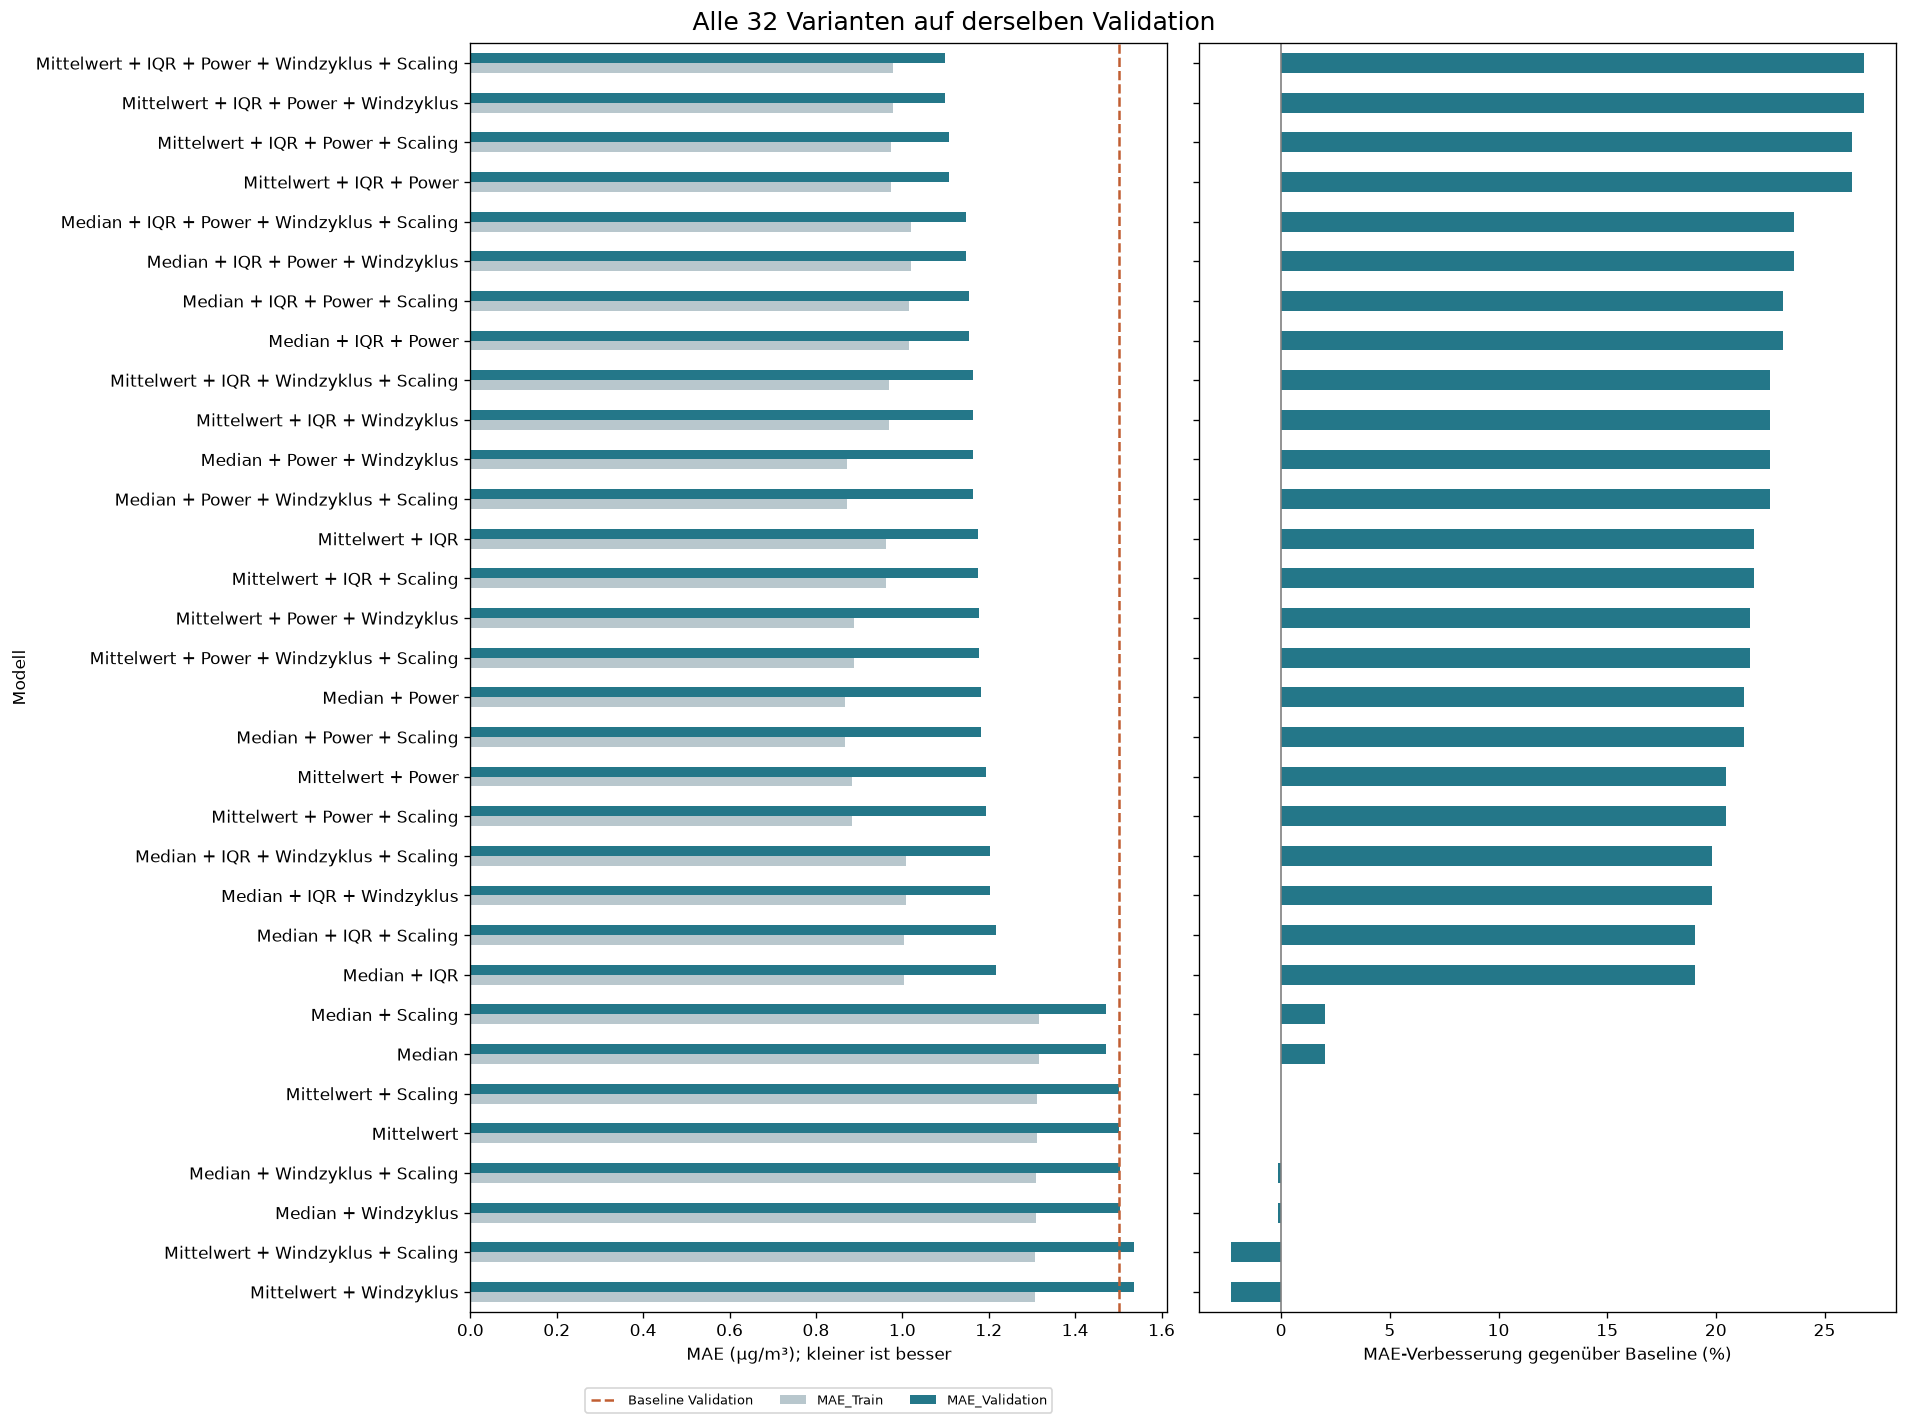

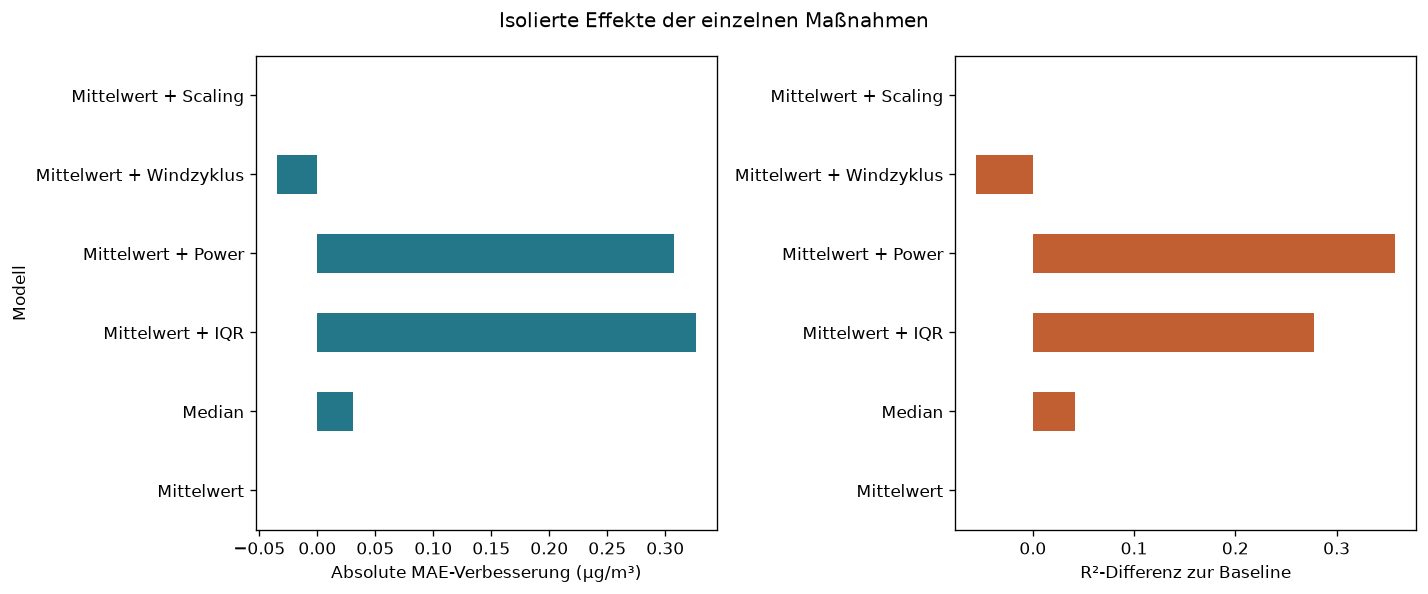

In [13]:
plot_data = results.sort_values('MAE_Validation', ascending=False).set_index('Modell')
fig, axes = plt.subplots(1, 2, figsize=(16, 12), sharey=True)
plot_data[['MAE_Train','MAE_Validation']].plot.barh(ax=axes[0], color=['#b8c7cd','#247789'])
axes[0].axvline(baseline_result['MAE_Validation'], color='#c15e32', linestyle='--', label='Baseline Validation')
axes[0].set_xlabel('MAE (µg/m³); kleiner ist besser')
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.055), ncol=3, fontsize=8)
plot_data['MAE_Gewinn_pct'].plot.barh(ax=axes[1], color='#247789')
axes[1].axvline(0, color='grey', linewidth=1)
axes[1].set_xlabel('MAE-Verbesserung gegenüber Baseline (%)')
axes[1].set_ylabel('')
fig.suptitle('Alle 32 Varianten auf derselben Validation', fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES / 'all_variants_mae.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
single_results.set_index('Modell')['MAE_Gewinn_abs'].plot.barh(ax=axes[0], color='#247789')
axes[0].set_xlabel('Absolute MAE-Verbesserung (µg/m³)')
single_results.set_index('Modell')['R2_Delta'].plot.barh(ax=axes[1], color='#c15e32')
axes[1].set_xlabel('R²-Differenz zur Baseline')
axes[1].set_ylabel('')
fig.suptitle('Isolierte Effekte der einzelnen Maßnahmen')
fig.tight_layout()
fig.savefig(FIGURES / 'single_step_deltas.png', bbox_inches='tight')
plt.show()

## 13. Kombinationen und Scaling erklären
**Kombinationseffekt:** Für Median und IQR vergleichen wir den gemeinsamen MAE-Gewinn mit der Summe der isolierten Gewinne. Die Differenz ist eine deskriptive Interaktion auf diesem Split, kein statistischer Kausalnachweis.

**Scaling:** Bei unregularisierter linearer Regression mit Intercept ändert eine invertierbare affine Skalierung den aufspannbaren Modellraum nicht. Koeffizienten und Intercept können dieselben Vorhersagen darstellen. Unterschiedliche Größenordnungen bedeuten bei OLS deshalb nicht automatisch eine inhaltliche Dominanz; numerische Rundungsunterschiede sind möglich. Das korrigiert die pauschale Behauptung aus dem alten Projekt.

In [14]:
lookup = results.set_index('Modell')
base_mae = baseline_result['MAE_Validation']
gain_median = base_mae - lookup.loc['Median','MAE_Validation']
gain_iqr = base_mae - lookup.loc['Mittelwert + IQR','MAE_Validation']
gain_combined = base_mae - lookup.loc['Median + IQR','MAE_Validation']
interaction = pd.DataFrame({'Vergleich': ['Median allein', 'IQR allein', 'Median + IQR', 'Summe isolierter Gewinne', 'Zusätzlicher Kombinationseffekt'],
    'MAE_Gewinn': [gain_median, gain_iqr, gain_combined, gain_median+gain_iqr, gain_combined-gain_median-gain_iqr]})
display(interaction.round(6))
interaction.to_csv(RESULTS / 'combination_effect.csv', index=False)

scale_pairs = []
for name, (state, model) in artifacts.items():
    if not state['config']['scaling']:
        scaled_config = state['config'].copy()
        scaled_config['scaling'] = True
        scaled_name = config_name(scaled_config)
        scaled_state, scaled_model = artifacts[scaled_name]
        prediction = model.predict(apply_preparation(validation, state))
        scaled_prediction = scaled_model.predict(apply_preparation(validation, scaled_state))
        scale_pairs.append({'Modell_ohne_Scaling': name,
            'MAE_Differenz_mit_minus_ohne': lookup.loc[scaled_name,'MAE_Validation'] - lookup.loc[name,'MAE_Validation'],
            'max_prediction_difference': np.max(np.abs(scaled_prediction - prediction))})
scaling_comparison = pd.DataFrame(scale_pairs)
display(scaling_comparison)
scaling_comparison.to_csv(RESULTS / 'scaling_pairs.csv', index=False)

,Vergleich,MAE_Gewinn
0,Median allein,0.030504
1,IQR allein,0.326401
2,Median + IQR,0.285787
3,Summe isolierter Gewinne,0.356905
4,Zusätzlicher Kombinationseffekt,-0.071118


,Modell_ohne_Scaling,MAE_Differenz_mit_minus_ohne,max_prediction_difference
0,Mittelwert,-2.220446e-16,6.039613e-14
1,Median,-2.220446e-14,2.664535e-13
2,Mittelwert + IQR,3.552714e-15,1.083578e-13
3,Mittelwert + Power,3.108624e-15,9.592327e-14
4,Mittelwert + Windzyklus,-1.398881e-14,1.416645e-13
5,Mittelwert + Power + Windzyklus,8.215650e-15,5.062617e-14
6,Mittelwert + IQR + Windzyklus,-3.552714e-15,8.704149e-14
7,Mittelwert + IQR + Power,-1.376677e-14,1.527667e-13
8,Mittelwert + IQR + Power + Windzyklus,-6.217249e-15,1.780798e-13
9,Median + Windzyklus,-5.773160e-15,4.662937e-14


## 14. Modell ausschließlich anhand Validation auswählen
Bei numerischem Gleichstand gewinnt die Variante mit weniger optionalen Maßnahmen. Es wird **nicht** automatisch die letzte oder aufwendigste Kombination übernommen. Das Modell bleibt auf dem ursprünglichen Training gefittet: kein Refit auf Training + Validation, damit die drei CSV-Dateien eine saubere Übergabe für Task 3 bilden.

**Ausgewählt: Mittelwert + IQR + Power + Windzyklus.** Validation-MAE: **1.0988 µg/m³**; R²: **0.3126**; MAE-Verbesserung: **26.83%**. Training-MAE: 0.9782; Validation–Training-Abstand: 0.1206.

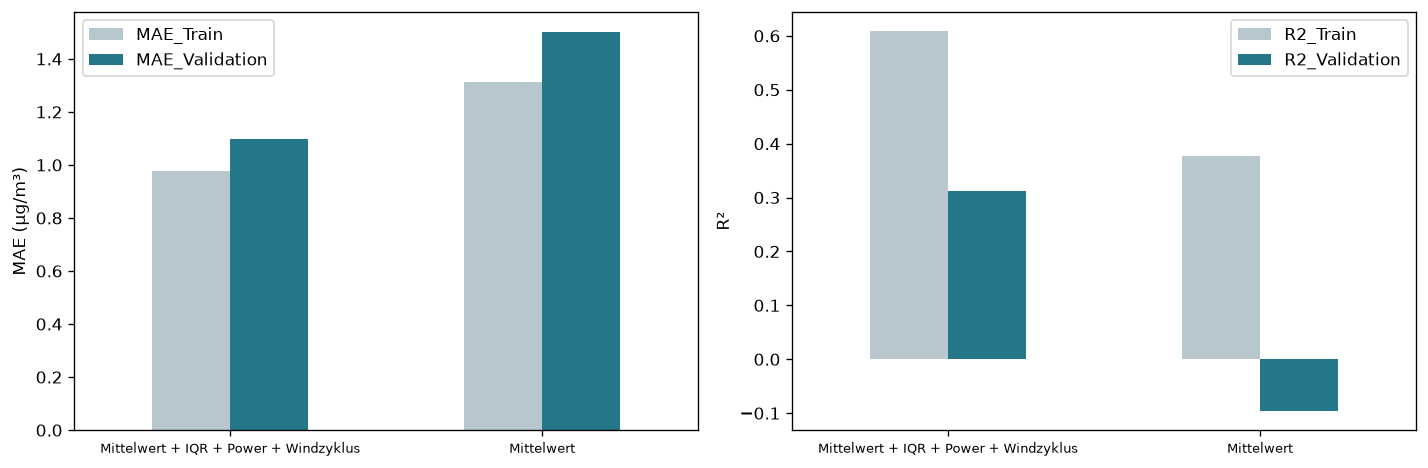

In [15]:
candidates = results.loc[results['MAE_Validation'] <= results['MAE_Validation'].min() + 1e-8]
best = candidates.sort_values(['n_optional','Modell']).iloc[0]
best_name = best['Modell']
best_state, best_model = artifacts[best_name]
selection = {'model': best_name, 'config': best_state['config'],
             'validation_mae': float(best['MAE_Validation']), 'validation_r2': float(best['R2_Validation']),
             'rule': 'Minimum Validation-MAE; Toleranz 1e-8, dann weniger optionale Schritte; kein Testzugriff',
             'refit_on_train_plus_validation': False}
(RESULTS / 'selected_model.json').write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding='utf-8')
display(Markdown(f"**Ausgewählt: {best_name}.** Validation-MAE: **{best['MAE_Validation']:.4f} µg/m³**; "
    f"R²: **{best['R2_Validation']:.4f}**; MAE-Verbesserung: **{best['MAE_Gewinn_pct']:.2f}%**. "
    f"Training-MAE: {best['MAE_Train']:.4f}; Validation–Training-Abstand: {best['MAE_Gap']:.4f}."))
# Visualisierung zur Überanpassungsprüfung, beide Metriken.
selected_comparison = results.loc[results['Modell'].isin([baseline_result['Modell'],best_name])].set_index('Modell')
fig, axes = plt.subplots(1,2,figsize=(12,4))
selected_comparison[['MAE_Train','MAE_Validation']].plot.bar(ax=axes[0], rot=0, color=['#b8c7cd','#247789'])
selected_comparison[['R2_Train','R2_Validation']].plot.bar(ax=axes[1], rot=0, color=['#b8c7cd','#247789'])
for ax in axes:
    ax.set_xlabel(''); ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('MAE (µg/m³)')
axes[1].set_ylabel('R²')
fig.tight_layout()
fig.savefig(FIGURES / 'overfitting_comparison.png', bbox_inches='tight')
plt.show()

## 15. Nachvollziehen, was die gewählte Vorbereitung verändert
Die folgende Übersicht quantifiziert IQR-Eingriffe, ursprüngliche Missings und die Imputationswerte. Diese Dokumentation macht sichtbar, ob eine Verbesserung mit vielen ersetzten Messwerten erkauft wird. Die Schwellen kommen weiterhin ausschließlich aus dem Training.

In [16]:
X_repr = represent_features(training, best_state['origin'], best_state['config']['cyclic'])
X_after_outliers = apply_outliers(X_repr, best_state['bounds']) if best_state['bounds'] is not None else X_repr.copy()
preparation_audit = pd.DataFrame({'missing_before': X_repr[best_state['numeric']].isna().sum(),
    'missing_after_outliers': X_after_outliers[best_state['numeric']].isna().sum(),
    'imputation_value': best_state['imputer'].statistics_})
preparation_audit['additional_outliers'] = preparation_audit['missing_after_outliers'] - preparation_audit['missing_before']
display(preparation_audit)
preparation_audit.to_csv(RESULTS / 'selected_preparation_audit.csv')
if best_state['bounds'] is not None:
    best_state['bounds'].to_csv(RESULTS / 'selected_iqr_bounds.csv')
if best_state['power'] is not None:
    pd.DataFrame({'feature': POWER_FEATURES, 'lambda': best_state['power'].lambdas_}).to_csv(RESULTS / 'selected_power_parameters.csv', index=False)
# IQR-Eingriffe auch dann transparent machen, wenn OH nicht gewählt wird.
fit_outliers(represent_features(training, baseline_state['origin'])).to_csv(RESULTS / 'candidate_iqr_bounds.csv')

,missing_before,missing_after_outliers,imputation_value,additional_outliers
pm25_lowcost,326,470,2.892193,144
no,10,287,1.384160,277
no2,10,83,6.971456,73
o3,208,211,26.765495,3
co2,333,356,459.080687,23
black_carbon,0,163,0.602236,163
ufp,576,631,9319.047397,55
temperature,391,391,18.915704,0
relative_humidity,391,391,71.469058,0
pressure,391,391,1008.358980,0


## 16. Einmaliger Abschlusstest der festgelegten Variante
**Erst hier wird `pm25_test.csv` geöffnet.** Keine weitere Auswahl nach dem Test. Es gibt bewusst keine nachträgliche Testbewertung sämtlicher Varianten. Die absoluten und relativen Baseline-Vergleiche stehen auf Validation; der finale Test misst ausschließlich das ausgewählte Modell.

Unbekannte Monatskategorien werden gemäß Pipeline-Lab mit `handle_unknown='ignore'` kodiert. Sie erhalten dieselben Nullen wie die Referenzkategorie; das ist eine dokumentierte Einschränkung, keine gelernte Wirkung des neuen Monats. Eine mögliche Warnung des Encoders bleibt sichtbar.

In [17]:
test = pd.read_csv(DATA / 'pm25_test.csv')
assert test.shape == (1464, 17)
assert list(test.columns) == list(original_train.columns)
test_labels_before = test[TARGET].copy()
test_index_before = test.index.copy()
X_train_final = apply_preparation(training, best_state)
X_val_final = apply_preparation(validation, best_state)
X_test_final = apply_preparation(test, best_state)
assert X_train_final.columns.equals(X_val_final.columns)
assert X_train_final.columns.equals(X_test_final.columns)
test_prediction = best_model.predict(X_test_final)
test_result = metrics(test[TARGET], test_prediction)
test_results = pd.DataFrame([{'Modell': best_name, **test_result}])
display(test_results)
test_results.to_csv(RESULTS / 'final_test_metrics.csv', index=False)
known_months = set(best_state['encoder'].categories_[0])
unknown_months = sorted(set(test['year_month']) - known_months)
print('Testmonate ohne Trainingskategorie:', unknown_months)
print('Nicht bewertbare Testlabels:', int(test[TARGET].isna().sum()))
print('Testlabels und Zeilen bleiben vollständig erhalten.')

/Users/kevin/Documents/ChatGPT/Data Science Projekt/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Modell,MAE,R2,n_rows,n_scored
0,Mittelwert + IQR + Power + Windzyklus,2.488058,-0.532862,1464,1419


Testmonate ohne Trainingskategorie: ['2024-11', '2024-12']
Nicht bewertbare Testlabels: 45
Testlabels und Zeilen bleiben vollständig erhalten.


## 17. CSV-Export für Task 3 und Integritätskontrollen
Die Feature-Spalten aller drei Dateien sind identisch. Das Label bleibt in ursprünglichen Einheiten. Die ursprüngliche CSV-Zeilennummer (0-basiert, ohne Kopfzeile) liegt in separaten Manifesten, damit sie nicht versehentlich als Feature genutzt wird.

Die Trainingsdatei enthält nur tatsächlich für den Fit verwendete Zeilen. Alle entfernten Trainingszeilen sind protokolliert. **Validation und Test werden vollständig exportiert**, auch wenn Labels fehlen. Task 3 muss für Metriken dieselbe Labelmaske verwenden. Keine neue Skalierung oder Imputation auf Validation/Test fitten.

In [18]:
exports = {}
for split_name, raw, prepared in [('train',training,X_train_final), ('validation',validation,X_val_final), ('test',test,X_test_final)]:
    exported = prepared.copy()
    exported[TARGET] = raw[TARGET]
    assert len(exported) == len(raw)
    pd.testing.assert_series_equal(exported[TARGET], raw[TARGET])
    path = RESULTS / f'pm25_preprocessed_{split_name}.csv'
    exported.to_csv(path, index=False)
    reread = pd.read_csv(path)
    assert len(reread) == len(raw)
    np.testing.assert_allclose(reread[TARGET], raw[TARGET], equal_nan=True)
    assert np.isfinite(reread.drop(columns=TARGET).to_numpy()).all()
    pd.DataFrame({'source_file': 'pm25_test.csv' if split_name == 'test' else 'pm25_train.csv',
        'source_row': raw.index, 'timestamp': raw['timestamp'].to_numpy()}).to_csv(RESULTS / f'row_manifest_{split_name}.csv', index=False)
    exports[split_name] = exported
pd.testing.assert_series_equal(validation[TARGET], validation_labels_before)
pd.testing.assert_series_equal(test[TARGET], test_labels_before)
assert validation.index.equals(validation_index_before)
assert test.index.equals(test_index_before)
assert len(exports['validation']) == 723 and len(exports['test']) == 1464
assert exports['train'].columns.equals(exports['validation'].columns)
assert exports['train'].columns.equals(exports['test'].columns)
# Das exportierte Training reproduziert das ausgewählte Modell ohne weiteres Preprocessing.
roundtrip_model = LinearRegression().fit(pd.read_csv(RESULTS / 'pm25_preprocessed_train.csv').drop(columns=TARGET),
                                       pd.read_csv(RESULTS / 'pm25_preprocessed_train.csv')[TARGET])
np.testing.assert_allclose(roundtrip_model.predict(pd.read_csv(RESULTS / 'pm25_preprocessed_test.csv').drop(columns=TARGET)),
                           test_prediction, rtol=1e-7, atol=1e-7)
pd.DataFrame({'source_row': test.index, 'pm25_target': test[TARGET], 'prediction': test_prediction}).to_csv(RESULTS / 'test_predictions.csv', index=False)
print('Prüfungen bestanden: Zeilen, Labelwerte, Featurelayout, endliche Features und CSV-Roundtrip.')
display(pd.DataFrame([{'Datei': key, 'Zeilen': len(value), 'Features': value.shape[1]-1} for key,value in exports.items()]))

Prüfungen bestanden: Zeilen, Labelwerte, Featurelayout, endliche Features und CSV-Roundtrip.


,Datei,Zeilen,Features
0,train,2686,20
1,validation,723,20
2,test,1464,20


## 18. Aus den Ergebnissen lernen
Die Zahlen werden aus den tatsächlich ausgeführten Versuchen übernommen. Das verhindert, dass Diagramme, Vortrag und finale Dateien unterschiedliche Modellstände beschreiben.

In [19]:
best_single = single_results.sort_values('MAE_Validation').iloc[0]
learnings = f"""# Ergebnisse und Learnings

- **Baseline:** Validation-MAE {baseline_result['MAE_Validation']:.4f} µg/m³; R² {baseline_result['R2_Validation']:.4f}. Alle 16 Ausgangsfeatures sind repräsentiert.
- **Stärkste isolierte Variante:** {best_single['Modell']}, MAE {best_single['MAE_Validation']:.4f}. Einzelmaßnahmen sind nicht automatisch in Kombination besser.
- **Ausgewählt aus 32 Varianten:** {best_name}; Validation-MAE {best['MAE_Validation']:.4f}; R² {best['R2_Validation']:.4f}.
- **Baseline-Verbesserung:** {best['MAE_Gewinn_abs']:.4f} µg/m³ bzw. {best['MAE_Gewinn_pct']:.2f}%; R²-Differenz {best['R2_Delta']:.4f}.
- **Median + IQR:** gemeinsamer Gewinn {gain_combined:.4f}; Summe der isolierten Gewinne {gain_median+gain_iqr:.4f}; zusätzliche Interaktion {gain_combined-gain_median-gain_iqr:.4f} µg/m³. Die Wirkung ist nicht einfach additiv.
- **Scaling:** maximale absolute MAE-Änderung über die 16 Paarvergleiche {scaling_comparison['MAE_Differenz_mit_minus_ohne'].abs().max():.2e}. Standardisierung ist hier kein automatischer Qualitätsgewinn.
- **Generalisierung:** Training-MAE {best['MAE_Train']:.4f}, Validation-MAE {best['MAE_Validation']:.4f}; Abstand {best['MAE_Gap']:.4f}. Ein Abstand kann Überanpassung oder zeitliche Verteilungsänderungen widerspiegeln; ein einzelner Split trennt beides nicht sicher.
- **Finaler Test:** MAE {test_result['MAE']:.4f} µg/m³; R² {test_result['R2']:.4f}; bewertet {test_result['n_scored']} von {test_result['n_rows']} Zeilen. Alle Testzeilen exportiert, Labels unverändert.
- **Übergabe:** {len(training)} Trainingszeilen, {len(validation)} Validierungszeilen und {len(test)} Testzeilen, jeweils {X_train_final.shape[1]} vorbereitete Features. Kein Refit auf Validation.

## Deutung des Testbefunds

Der negative Test-R² bedeutet einen höheren quadratischen Fehler als die konstante Vorhersage des Mittelwerts der beobachteten Testlabels. Das Modell liefert somit keinen überzeugenden Nachweis präziser Kalibrierung für spätere Monate. Die Verbesserung auf Validation darf diesen Befund nicht verdecken.

## Grenzen und offene fachliche Punkte

- Keine aktuelle Task-1-Zusammenfassung vorhanden. Diagnosen und Maßnahmen mit dem Team abgleichen.
- Die Zeitdarstellung als linearer Trend und redundantes year_month sind eine minimale technische Repräsentation, keine behauptete physikalische Ursache.
- Unbekannte Testmonate: {unknown_months}; OHE fällt auf die Nullkodierung zurück. Zeitliche Drift und Extrapolation können Testfehler erhöhen.
- Statistik allein belegt keine Sensorfehler. IQR-Behandlung kann reale Schadstoffspitzen ersetzen; gegebenenfalls fachlich prüfen.
- Fehlende Labels erlauben dort keine Fehlerberechnung. Fehlende Sensorwerte sind nicht automatisch zufällig; die Diagnose beweist weder MCAR noch MAR.
- Auswahl unter 32 Varianten auf nur einem Validierungssplit; keine Behauptung universeller Überlegenheit oder garantierter Punktzahl.
- Feature Selection und andere Modellalgorithmen gehören entsprechend Feedback nicht in diese Umsetzung von Task 2.
"""
display(Markdown(learnings))
(RESULTS / 'LEARNINGS.md').write_text(learnings, encoding='utf-8')
# Kleine, maschinenlesbare Grundlage für die Präsentation, keine zusätzlichen Modellversuche.
presentation_data = {'baseline': baseline_result, 'best': best.to_dict(), 'test': test_result,
    'single': single_results.to_dict(orient='records'), 'interaction': interaction.to_dict(orient='records'),
    'n_train': len(training), 'n_validation': len(validation), 'n_test': len(test),
    'n_features': X_train_final.shape[1], 'unknown_months': unknown_months,
    'max_scaling_mae_difference': float(scaling_comparison['MAE_Differenz_mit_minus_ohne'].abs().max())}
(RESULTS / 'presentation_data.json').write_text(json.dumps(presentation_data, indent=2, ensure_ascii=False), encoding='utf-8')

# Ergebnisse und Learnings

- **Baseline:** Validation-MAE 1.5017 µg/m³; R² -0.0962. Alle 16 Ausgangsfeatures sind repräsentiert.
- **Stärkste isolierte Variante:** Mittelwert + IQR, MAE 1.1753. Einzelmaßnahmen sind nicht automatisch in Kombination besser.
- **Ausgewählt aus 32 Varianten:** Mittelwert + IQR + Power + Windzyklus; Validation-MAE 1.0988; R² 0.3126.
- **Baseline-Verbesserung:** 0.4029 µg/m³ bzw. 26.83%; R²-Differenz 0.4089.
- **Median + IQR:** gemeinsamer Gewinn 0.2858; Summe der isolierten Gewinne 0.3569; zusätzliche Interaktion -0.0711 µg/m³. Die Wirkung ist nicht einfach additiv.
- **Scaling:** maximale absolute MAE-Änderung über die 16 Paarvergleiche 1.01e-13. Standardisierung ist hier kein automatischer Qualitätsgewinn.
- **Generalisierung:** Training-MAE 0.9782, Validation-MAE 1.0988; Abstand 0.1206. Ein Abstand kann Überanpassung oder zeitliche Verteilungsänderungen widerspiegeln; ein einzelner Split trennt beides nicht sicher.
- **Finaler Test:** MAE 2.4881 µg/m³; R² -0.5329; bewertet 1419 von 1464 Zeilen. Alle Testzeilen exportiert, Labels unverändert.
- **Übergabe:** 2686 Trainingszeilen, 723 Validierungszeilen und 1464 Testzeilen, jeweils 20 vorbereitete Features. Kein Refit auf Validation.

## Deutung des Testbefunds

Der negative Test-R² bedeutet einen höheren quadratischen Fehler als die konstante Vorhersage des Mittelwerts der beobachteten Testlabels. Das Modell liefert somit keinen überzeugenden Nachweis präziser Kalibrierung für spätere Monate. Die Verbesserung auf Validation darf diesen Befund nicht verdecken.

## Grenzen und offene fachliche Punkte

- Keine aktuelle Task-1-Zusammenfassung vorhanden. Diagnosen und Maßnahmen mit dem Team abgleichen.
- Die Zeitdarstellung als linearer Trend und redundantes year_month sind eine minimale technische Repräsentation, keine behauptete physikalische Ursache.
- Unbekannte Testmonate: ['2024-11', '2024-12']; OHE fällt auf die Nullkodierung zurück. Zeitliche Drift und Extrapolation können Testfehler erhöhen.
- Statistik allein belegt keine Sensorfehler. IQR-Behandlung kann reale Schadstoffspitzen ersetzen; gegebenenfalls fachlich prüfen.
- Fehlende Labels erlauben dort keine Fehlerberechnung. Fehlende Sensorwerte sind nicht automatisch zufällig; die Diagnose beweist weder MCAR noch MAR.
- Auswahl unter 32 Varianten auf nur einem Validierungssplit; keine Behauptung universeller Überlegenheit oder garantierter Punktzahl.
- Feature Selection und andere Modellalgorithmen gehören entsprechend Feedback nicht in diese Umsetzung von Task 2.


5669

### Interpretation dieser Ausführung

- **IQR ist die stärkste isolierte MAE-Maßnahme**: von 1,5017 auf 1,1753 µg/m³. Das stützt die Hypothese, dass große Schadstoffmesswerte die Baseline beeinträchtigen. Es beweist nicht, dass alle ersetzten Werte Messfehler waren.
- **Power allein verbessert R² stärker als IQR allein**, obwohl IQR den kleineren MAE erreicht. MAE und R² priorisieren Fehler unterschiedlich: R² hängt an quadrierten Abweichungen. Die Auswahlregel MAE wird deshalb vorab festgelegt.
- **Median ist nicht automatisch robuster im Gesamtablauf**: Median allein hilft leicht, Median + IQR bleibt aber hinter Mittelwert + IQR zurück. Nach dem Ersetzen von Spitzen können Mittelwerte wieder besser passen; die Kombinationseffekte sind nicht additiv.
- **Windzyklus allein verschlechtert MAE**, ist aber Teil der besten Kombination. Daraus folgt gerade nicht, dass man alle isoliert schwächeren Schritte sofort ausschließen sollte. Das rechtfertigt den Kombinationsvergleich.
- **Scaling verändert die Güte nur in numerischer Rundungsgröße**. Die inhaltliche Dominanz großer Zahlen war im alten Projekt zu pauschal beschrieben.
- **Der Test widerspricht einer starken Generalisierungsbehauptung**: MAE 2,4881 und R² −0,5329 sind deutlich schlechter als die Validation. Im quadratischen Fehler ist das Modell schlechter als eine konstante Vorhersage des Mittelwerts der 1.419 beobachteten Testlabels. Das ist ein ernstes Ergebnis und kein erfolgreicher Nachweis präziser Kalibrierung für spätere Monate.
- November und Dezember waren keine Trainingskategorien. Ihre OHE-Nullkodierung und die zeitliche Extrapolation sind mögliche Schwächen. Aus den vorhandenen Kennzahlen lässt sich die genaue Ursache nicht beweisen. Kein nachträgliches Ausprobieren mit Testlabels; solche Fragen gehen als dokumentierte Hypothesen an die nächste Arbeitsphase.


## 19. Abgabe und Quellen

Die Präsentation folgt der Aufgabenstellung: Baseline, Datenqualität/Maßnahmen, isolierte und kombinierte Effekte, Overfitting, finaler Test, Learnings. Keine Codefolien. Das ausgeführte Notebook, die beiden verwendeten Rohdatendateien, die drei vorbereiteten CSVs, Logs und Präsentation gehören gemeinsam in die ZIP-Abgabe.

**Lokale Quellen:** Case Study Description S. 8, 10–11, 15; `Feedback.md`; `old_Abgabe_Task2.ipynb`; Missing Value Handling, Outlier Handling, Transformation, Scaling, Regression und Pipeline-Labs; zugehörige Vorlesungen. Der genaue Abgleich der Quellen und aller bewussten Anpassungen steht in `QUELLEN_UND_ENTSCHEIDUNGEN.md`. Keine externen fachlichen Quellen oder Methoden hinzugefügt.